In [1]:
#IMPORTS
from sklearn.preprocessing import PowerTransformer, StandardScaler
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns
import pandas as pd
import numpy as np
import math
import re
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness

In [2]:
#CONFIGURACOES
# ---- nao truncar impressao do pandas ---- #
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)
# ----------------------------------------- #

In [3]:
df = pd.read_csv("dados/Dados_REG_limpo_baseline.csv", sep="\t")
df["Atividade 03"].value_counts()

Atividade 03
Negativo    475
Positivo     28
Name: count, dtype: int64

# Limpeza das atividades

In [4]:
#pega so as colunas de atividade
ensaios = [c for c in df.columns if c.startswith("Atividade ")]
X = df[ensaios].copy()
X.tail()

,Atividade 01,Atividade 02,Atividade 03,Atividade 04,Atividade 05,Atividade 06,Atividade 07,Atividade 08,Atividade 09,Atividade 10,Atividade 11,Atividade 12,Atividade 13,Atividade 14,Atividade 15,Atividade 16,Atividade 17,Atividade 18,Atividade 19,Atividade 20,Atividade 21,Atividade 22,Atividade 23
498,0,0.0,Positivo,Negativo,0.00,0.00,0.27,0.03,0.50,0.32,0.26,0.24,1,0.0,0.00,Positivo,3,0,1,NaN,NaN,0,3.422
499,0,1.6,Negativo,Negativo,0.00,0.03,0.01,0.01,0.09,0.31,0.20,0.15,3,0.0,0.00,Negativo,2,2,3,3.0,3.0,2,7.210
500,0,2.2,Positivo,Negativo,1.00,0.00,0.24,0.02,0.19,0.40,0.15,0.11,2,0.0,3.75,Positivo,3,3,3,3.0,3.0,3,6.137
501,0,0.0,Positivo,Negativo,1.17,0.01,-0.06,-0.02,0.57,0.35,0.28,0.23,2,0.0,0.00,Positivo,1,0,3,3.0,1.0,1,5.695
502,0,0.0,Positivo,Negativo,1.00,0.00,0.17,-0.02,0.69,0.54,0.18,0.10,0,0.0,0.00,Positivo,1,0,0,3.0,0.0,0,27.252


In [5]:
#transforma string em binario
for c in X.columns:
    if pd.api.types.is_string_dtype(X[c]):
        X[c] = X[c].map({"Positivo": 1, "Negativo": 0})
X.tail()

,Atividade 01,Atividade 02,Atividade 03,Atividade 04,Atividade 05,Atividade 06,Atividade 07,Atividade 08,Atividade 09,Atividade 10,Atividade 11,Atividade 12,Atividade 13,Atividade 14,Atividade 15,Atividade 16,Atividade 17,Atividade 18,Atividade 19,Atividade 20,Atividade 21,Atividade 22,Atividade 23
498,0,0.0,1,0,0.00,0.00,0.27,0.03,0.50,0.32,0.26,0.24,1,0.0,0.00,1,3,0,1,NaN,NaN,0,3.422
499,0,1.6,0,0,0.00,0.03,0.01,0.01,0.09,0.31,0.20,0.15,3,0.0,0.00,0,2,2,3,3.0,3.0,2,7.210
500,0,2.2,1,0,1.00,0.00,0.24,0.02,0.19,0.40,0.15,0.11,2,0.0,3.75,1,3,3,3,3.0,3.0,3,6.137
501,0,0.0,1,0,1.17,0.01,-0.06,-0.02,0.57,0.35,0.28,0.23,2,0.0,0.00,1,1,0,3,3.0,1.0,1,5.695
502,0,0.0,1,0,1.00,0.00,0.17,-0.02,0.69,0.54,0.18,0.10,0,0.0,0.00,1,1,0,0,3.0,0.0,0,27.252


In [6]:
#transforma os nulos em mediana
for c in ["Atividade 20", "Atividade 21"]:
    X[c] = X[c].fillna(X[c].median())

X.tail()

,Atividade 01,Atividade 02,Atividade 03,Atividade 04,Atividade 05,Atividade 06,Atividade 07,Atividade 08,Atividade 09,Atividade 10,Atividade 11,Atividade 12,Atividade 13,Atividade 14,Atividade 15,Atividade 16,Atividade 17,Atividade 18,Atividade 19,Atividade 20,Atividade 21,Atividade 22,Atividade 23
498,0,0.0,1,0,0.00,0.00,0.27,0.03,0.50,0.32,0.26,0.24,1,0.0,0.00,1,3,0,1,2.0,3.0,0,3.422
499,0,1.6,0,0,0.00,0.03,0.01,0.01,0.09,0.31,0.20,0.15,3,0.0,0.00,0,2,2,3,3.0,3.0,2,7.210
500,0,2.2,1,0,1.00,0.00,0.24,0.02,0.19,0.40,0.15,0.11,2,0.0,3.75,1,3,3,3,3.0,3.0,3,6.137
501,0,0.0,1,0,1.17,0.01,-0.06,-0.02,0.57,0.35,0.28,0.23,2,0.0,0.00,1,1,0,3,3.0,1.0,1,5.695
502,0,0.0,1,0,1.00,0.00,0.17,-0.02,0.69,0.54,0.18,0.10,0,0.0,0.00,1,1,0,0,3.0,0.0,0,27.252


In [7]:
#MOSTRANDO VALORES OUTLIERS EXTREMOS NOS DADOS (usei para ver quais colunas tratar outliers)
def outliers_iqr(column):
    serie = X[column]
    q1, q3 = serie.quantile([0.05, 0.95])
    iqr = q3 - q1
    #print(f"iqr {iqr}")
    if iqr == 0:
      return serie[(serie > 0) & (serie < 0)]
    limite_inf, limite_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    X[column].clip(lower = limite_inf, upper = limite_sup)
    return serie[(serie < limite_inf) | (serie > limite_sup)]

for c in X.columns:
  out = outliers_iqr(c)
  if len(out) > 0:
    print(f"{len(out)} outliers encontrados")
    print(c)
    print(out)

1 outliers encontrados
Atividade 14
195    15.5
Name: Atividade 14, dtype: float64
1 outliers encontrados
Atividade 15
69    20.0
Name: Atividade 15, dtype: float64
1 outliers encontrados
Atividade 23
455    577.893
Name: Atividade 23, dtype: float64


In [8]:
#transforma em log(1+n) pra reduzir o impacto dos outliers extremos
out_extremos = ["Atividade 14", "Atividade 15", "Atividade 23"]
for c in out_extremos:
    X[c] = np.log1p(X[c])

X

,Atividade 01,Atividade 02,Atividade 03,Atividade 04,Atividade 05,Atividade 06,Atividade 07,Atividade 08,Atividade 09,Atividade 10,Atividade 11,Atividade 12,Atividade 13,Atividade 14,Atividade 15,Atividade 16,Atividade 17,Atividade 18,Atividade 19,Atividade 20,Atividade 21,Atividade 22,Atividade 23
0,0,0.00,0,0,1.20,0.00,0.00,-0.01,0.76,0.54,0.74,0.06,1,0.000000,0.000000,1,1,1,3,1.0,3.0,0,1.326279
1,0,2.33,0,0,1.20,-0.01,0.13,-0.04,0.28,0.10,0.09,0.04,0,1.335001,1.386294,1,3,3,2,3.0,3.0,0,2.615789
2,0,3.50,0,0,1.38,0.00,0.43,0.01,0.12,0.26,0.27,0.14,0,1.098612,1.252763,1,3,3,3,3.0,3.0,3,2.063058
3,0,0.00,0,0,1.25,0.67,0.11,0.03,0.99,0.67,0.24,0.11,2,0.000000,0.000000,1,0,0,0,0.0,1.0,0,1.315872
4,0,1.75,0,0,1.20,0.00,0.10,-0.02,0.24,0.26,0.09,0.17,0,1.202972,0.788457,1,2,3,0,3.0,3.0,3,2.513899
5,0,0.00,0,1,1.25,0.01,0.02,-0.03,0.87,0.48,0.23,0.35,0,0.000000,0.000000,1,1,0,3,0.0,0.0,0,1.437225
6,0,2.25,0,0,1.33,0.01,0.11,-0.03,0.29,0.22,0.15,0.19,1,0.000000,0.000000,1,0,1,0,3.0,3.0,0,2.842056
7,0,2.50,0,1,1.40,0.00,0.14,-0.01,0.52,0.23,0.16,0.16,1,0.000000,0.000000,1,0,0,0,0.0,0.0,0,2.252554
8,0,0.00,0,0,1.50,0.01,0.13,0.00,1.36,0.63,0.24,0.05,1,0.000000,0.845868,1,0,0,3,0.0,0.0,0,1.109552
9,0,2.25,0,1,1.25,0.01,0.12,-0.01,0.56,0.21,0.17,0.15,1,0.000000,0.000000,1,0,1,3,1.0,0.0,0,3.601659


In [9]:
#normaliza as dimensoes

Xsc = StandardScaler().fit_transform(X)
print("Matriz final:", Xsc.shape)
Xsc

Matriz final: (503, 23)


array([[-0.2087306 , -0.75890773, -0.24279079, ...,  0.82805183,
        -0.86629432, -1.05853318],
       [-0.2087306 ,  1.10101212, -0.24279079, ...,  0.82805183,
        -0.86629432, -0.14193483],
       [-0.2087306 ,  2.03496329, -0.24279079, ...,  0.82805183,
         2.24617742, -0.53482211],
       ...,
       [-0.2087306 ,  0.99723977,  4.11877236, ...,  0.82805183,
         2.24617742, -0.60431498],
       [-0.2087306 , -0.75890773,  4.11877236, ..., -0.84132721,
         0.17119626, -0.64975826],
       [-0.2087306 , -0.75890773,  4.11877236, ..., -1.67601673,
        -0.86629432,  0.37367045]], shape=(503, 23))

In [10]:
#Faz o PCA, pegando as duas dimensoes com maior porcentagem da variancia
SEED = 150

pca = PCA(n_components=2, random_state=SEED)
Z_pca = pca.fit_transform(Xsc)
var_exp = pca.explained_variance_ratio_

Z_pca

array([[-0.96512682,  0.31643392],
       [ 2.73002228, -2.34266446],
       [ 3.76498836, -2.11256134],
       ...,
       [ 3.81751983, -2.06868226],
       [ 0.20667902, -0.8552346 ],
       [-1.44719534, -1.48117245]], shape=(503, 2))

#salva as coordenadas do PCA VVV

In [ ]:
colnas= ['PC1', 'PC2']

dimensoes = pd.DataFrame(Z_pca, columns=colnas)
dimensoes.to_csv('dados/dim_PCA.csv', index=False)
dimensoes

,PC1,PC2
0,-0.965127,0.316434
1,2.730022,-2.342664
2,3.764988,-2.112561
3,-3.692979,0.041298
4,2.570958,-1.966163
5,-2.322430,-0.285562
6,0.191161,-2.129145
7,-2.040749,-1.935673
8,-2.477763,0.269713
9,-0.710512,-1.746704


# **TROCA A LABEL AQUI VVV**

In [ ]:
#labels = np.asarray(resF.loc[0, "labels"])
labels = pd.read_csv('dados/Classe_HDBS_MDS.csv', sep="\t" ) # grafico para HDBSCAN
#labels = pd.read_csv('dados/Classe_K_PROTOTYPE.csv', sep="\t" ) # grafico para K-Prototypes
labels

,Classe_HDBS_MDS
0,6
1,7
2,0
3,5
4,7
5,5
6,-1
7,-1
8,5
9,-1


In [ ]:
arr = labels.iloc[:, 0].to_numpy()




arr

array([ 6,  7,  0,  5,  7,  5, -1, -1,  5, -1,  5, -1, -1,  7, -1, -1, -1,
        2,  1,  6,  7, -1,  7,  5,  7, -1,  5,  5, -1,  5,  3, -1,  6,  5,
        5, -1, -1,  1,  5,  5, -1,  6,  5,  5,  5,  6,  5,  1, -1, -1, -1,
       -1,  5,  5, -1, -1, -1, -1, -1,  1,  6,  5, -1, -1, -1, -1, -1, -1,
       -1, -1,  2,  6, -1, -1,  5,  5, -1,  5, -1, -1,  5,  1,  1,  7,  1,
       -1,  5,  6, -1,  7,  7,  7, -1,  2,  4,  1,  5,  5,  1,  1,  5,  5,
        5, -1, -1, -1,  5,  1,  5,  1,  5,  1,  1, -1, -1,  1,  1, -1, -1,
        5,  5,  1,  5, -1, -1,  1, -1, -1,  1,  7, -1,  2, -1, -1, -1,  4,
        6,  2,  1,  2, -1,  2, -1,  1, -1, -1, -1,  6,  1,  0,  2, -1,  1,
       -1, -1, -1,  1,  1, -1, -1, -1, -1, -1, -1,  7, -1,  3,  0,  1,  3,
        2,  2,  0, -1, -1,  2, -1,  1, -1,  7,  7, -1,  2, -1,  6, -1, -1,
       -1, -1,  5,  5, -1,  0,  1,  1,  1,  2,  2, -1, -1, -1, -1,  0, -1,
       -1,  4,  4,  0, -1, -1, -1, -1,  2, -1,  2,  0, -1,  0,  5, -1, -1,
        0, -1, -1,  6, -1

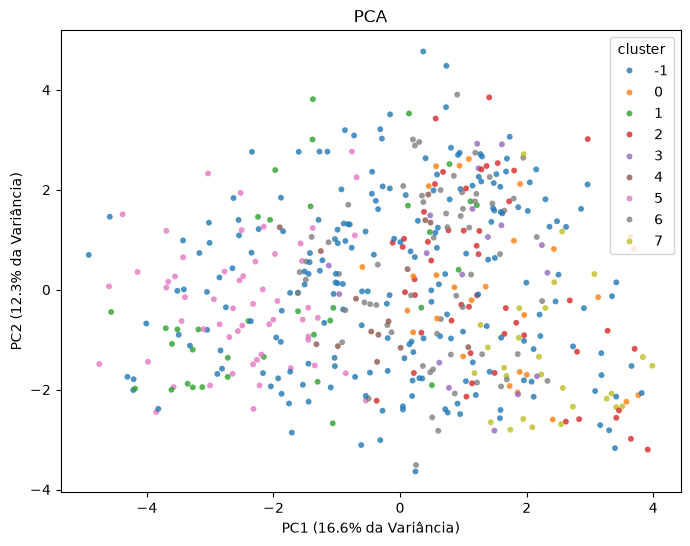

In [31]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z_pca[:, 0], y=Z_pca[:, 1], hue=arr,
              palette="tab10", s=18, alpha=0.8, edgecolor="none")
plt.title("PCA")
plt.xlabel(f"PC1 ({var_exp[0]:.1%} da Variância)")
plt.ylabel(f"PC2 ({var_exp[1]:.1%} da Variância)")
plt.legend(title="cluster")
plt.show()

In [32]:
#calcula o MSE ao tentar reconstruir as dimensoes
mse = []
for d in range(1, 23):
    m = PCA(n_components=d, random_state=SEED).fit(Xsc)
    X_inv = m.inverse_transform(m.transform(Xsc))
    mse.append(np.mean((Xsc - X_inv) ** 2))

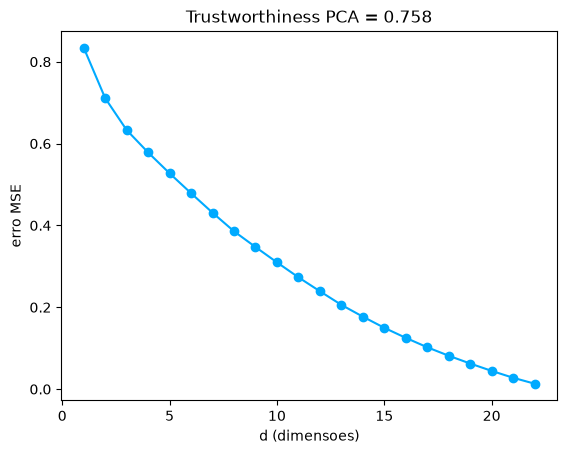

In [25]:
#monta o grafico, junto com a trustworthiness
plt.plot(range(1, 23), mse, "o-", c="#00AAFF")
plt.xlabel("d (dimensoes)")
plt.ylabel("erro MSE")
t_pca  = trustworthiness(Xsc, Z_pca)
plt.title(f"Trustworthiness PCA = {t_pca:.3f}")
plt.show()

In [26]:
#faz o t-SNE em duas dimensoes
tsne = TSNE(n_components=2, perplexity=30, random_state=SEED)
Z_tsne = tsne.fit_transform(Xsc)
t_tsne = trustworthiness(Xsc, Z_tsne)

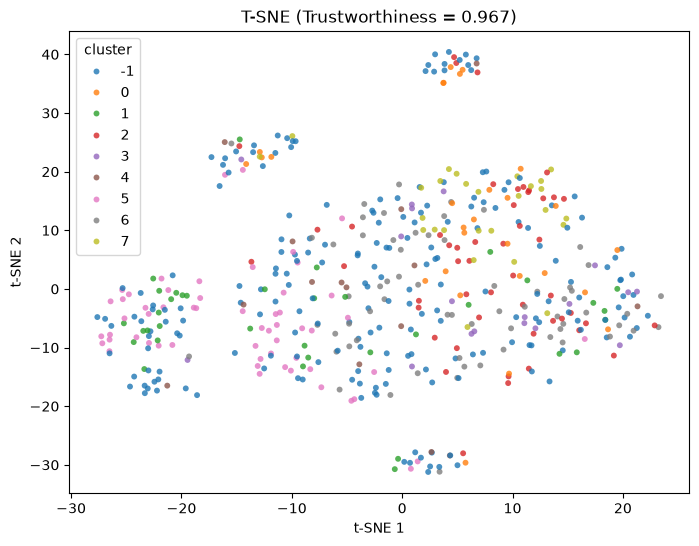

In [33]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z_tsne[:, 0], y=Z_tsne[:, 1], hue=arr,
              palette="tab10", s=18, alpha=0.8, edgecolor="none")
plt.title(f"T-SNE (Trustworthiness = {t_tsne:.3f})")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(title="cluster")
plt.show()

# Salva as coordenadas do TSNE VVV

In [ ]:
colnas= ['TSNE1', 'TSNE2']

dimensoes = pd.DataFrame(Z_tsne, columns=colnas)
dimensoes.to_csv('dados/dim_TSNE.csv', index=False)
dimensoes

,TSNE1,TSNE2
0,-5.955025,-10.700254
1,4.235501,20.436417
2,10.737934,20.489216
3,-22.939785,-9.214387
4,4.932523,19.640156
5,0.787653,-30.665997
6,-2.119530,11.294043
7,0.189371,-29.486473
8,-13.287477,-9.713523
9,0.709766,-29.650156


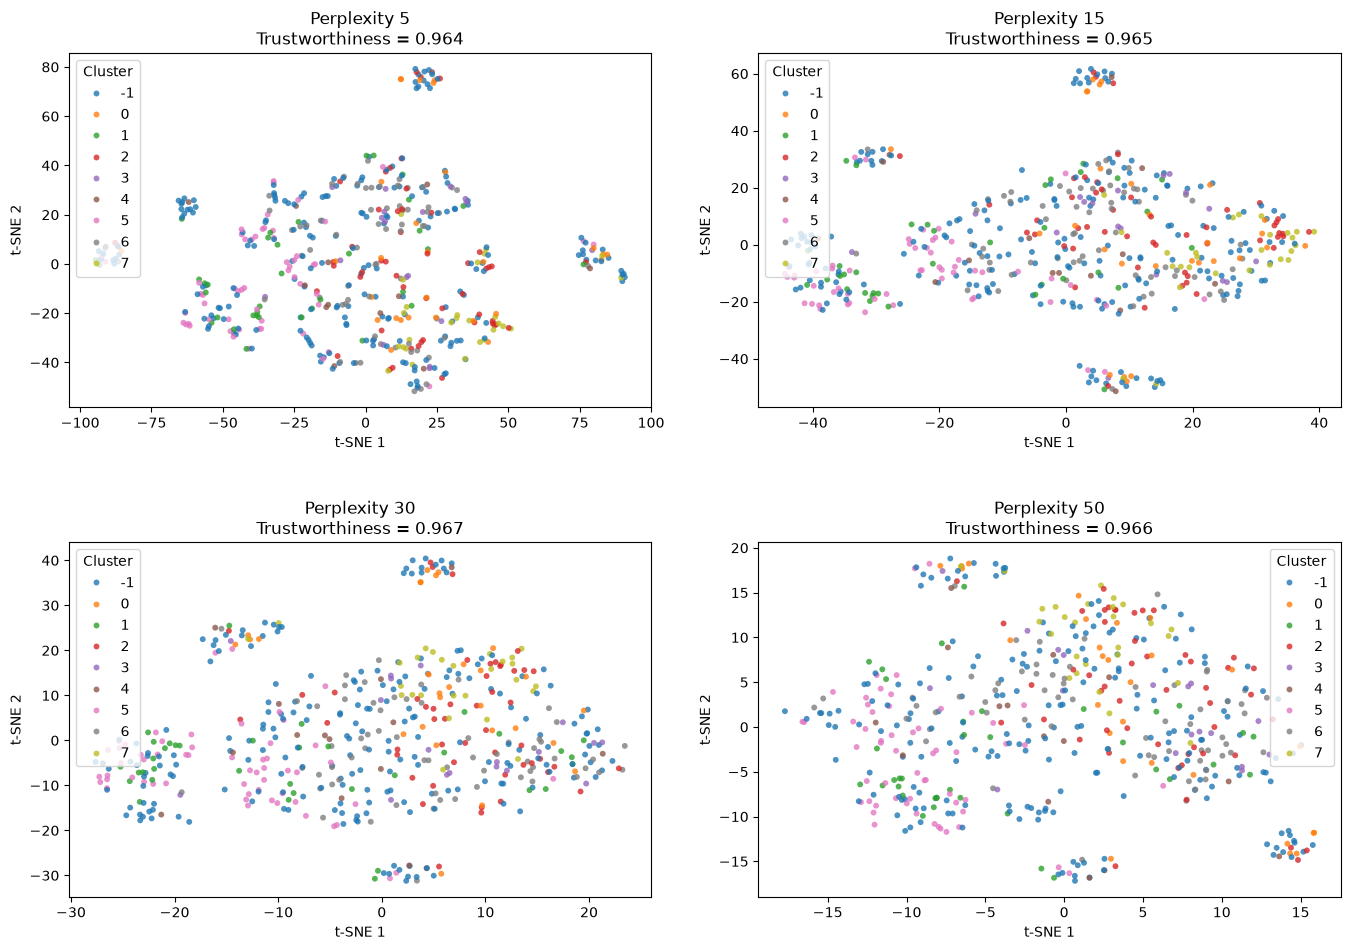

In [34]:
pp = [5, 15, 30, 50]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, p in zip(axes, pp):
    tsne_t = TSNE(n_components=2, perplexity=p, random_state=SEED)
    Z_tsne_t = tsne_t.fit_transform(Xsc)

    sns.scatterplot(
        x=Z_tsne_t[:, 0],
        y=Z_tsne_t[:, 1],
        hue=arr,
        palette="tab10",
        s=18,
        alpha=0.8,
        edgecolor="none",
        ax=ax
    )

    t_tsne_t = trustworthiness(Xsc, Z_tsne_t)

    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
    ax.set_title(f"Perplexity {p}\nTrustworthiness = {t_tsne_t:.3f}")

    ax.legend(title="Cluster")

plt.tight_layout(pad=2.5, h_pad=3.5, w_pad=2.5)
plt.show()